# 02 · Expression — EMT-transcription-factor overlay

*(Renumbered from 06: with **Gate 1 = NO-GO** the malignant compartment is a per-patient
archipelago, no trajectory is fit, and the manifold / signatures / correlation / modules notebooks
are **not** produced. This unconditional EMT-TF expression step is the final notebook, numbered 02.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus) as the two EMT-TFs marking the ends of
its trajectory. Per the **derive-don't-inherit** mandate we do not inherit that pair, and per the
evaluation / testing lessons we **widen** the canonical Snail/Zeb/Twist panel with the mesenchymal /
neural-crest **FOXC** and **PRRX** families and **exclude VIM** (vimentin is a mesenchymal *marker*,
not a transcription factor). Because there is **no trajectory**, TFs are ranked by **detectable
expression** (no pseudotime ordering) and the two broadest are overlaid as **thresholded expressers**
on the grey manifold — the reference categorical plotting style. Deliverable: `expression.pdf`.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the best-attempt manifold
`processed.h5ad` from 01 — the whole malignant compartment on its regenerated embedding (Gate 1
NO-GO, no trajectory, no pseudotime).

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('cells:', adata.shape[0], '| genes:', adata.shape[1], '| samples:', adata.obs['sample'].nunique())

cells: 4818 | genes: 17670 | samples: 7


### Derive the EMT-TFs to overlay (detection-gated; no pseudotime)
For each candidate TF: the fraction of malignant cells expressing it and the mean expression among
expressers. With no trajectory there is no early/late ordering, so we rank by **breadth of detectable
expression** and overlay the two broadest above a 3% expression floor. Factors below the floor are
too sparse to overlay honestly.

In [ ]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']  # VIM excluded (marker, not TF)
present = [g for g in panel if g in adata.var_names]
X = adata[:, present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rows.append((g, round(expr.mean(),3), round(float(x[expr].mean()) if expr.any() else 0.0, 3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_in_expr']).sort_values('frac_expr', ascending=False)
print('EMT-TF panel (VIM excluded as marker; ranked by detectable expression):')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
top2 = ok.head(2)['TF'].tolist()
print(f'\n3% expression floor -> {len(ok)} detectable TFs; two broadest for overlay: {top2}')
print('(no pseudotime: Gate 1 NO-GO means no trajectory, so TFs are ranked by breadth, not by trajectory end)')

EMT-TF panel (VIM excluded as marker; ranked by detectable expression):
    TF  frac_expr  mean_in_expr
 SNAI2      0.113         1.398
 FOXC1      0.104         0.473
 SNAI1      0.068         0.490
TWIST2      0.030         0.320
 PRRX1      0.026         0.512
 FOXC2      0.023         0.289
 PRRX2      0.019         0.270
  ZEB1      0.012         0.298
TWIST1      0.008         0.303
  ZEB2      0.005         0.478

3% expression floor -> 3 detectable TFs; two broadest for overlay: ['SNAI2', 'FOXC1']
(no pseudotime: Gate 1 NO-GO means no trajectory, so TFs are ranked by breadth, not by trajectory end)


### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, `size=30`, the two broadest EMT-TFs as **categorical thresholded
expressers** (each at the upper quartile of expression among its expressing cells) coloured over the
grey manifold — the reference plotting style, *not* a continuous single-gene colormap. Draw order by
abundance so neither marker is fully occluded. No pseudotime axis (no trajectory).

overlay thresholds (upper quartile among expressers): {'SNAI2': 1.903, 'FOXC1': 0.624} | cells shown: {'SNAI2': 137, 'FOXC1': 125}
SNAI2: 11.3% expressing; 137 shown (upper quartile)
FOXC1: 10.4% expressing; 125 shown (upper quartile)
saved expression.pdf


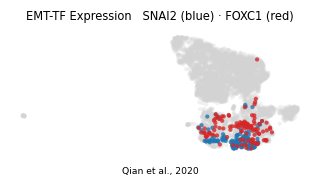

In [ ]:
def _vec(g):
    x = adata[:, g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in top2:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in top2}
order = sorted(top2, key=lambda g: -int(sel[g].sum()))
colors = {top2[0]:'tab:blue', top2[1]:'tab:red'}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in top2},
      '| cells shown:', {g: int(sel[g].sum()) for g in top2})

xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {top2[0]} (blue) · {top2[1]} (red)', size=7.5)
ax.text(.5,-.14,'Qian et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in top2:
    print(f'{g}: {( _vec(g)>0).mean()*100:.1f}% expressing; {int(sel[g].sum())} shown (upper quartile)')
print('saved expression.pdf')